In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    IsolationForest
)
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    brier_score_loss
)

from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
N_MACHINES = 120
N_DAYS = 365

dates = pd.date_range(
    start="2025-01-01",
    periods=N_DAYS,
    freq="D"
)

machine_types = ["Pump", "Compressor", "Turbine"]

records = []

for machine_num in range(N_MACHINES):

    machine_id = f"M{machine_num + 1:03d}"

    machine_type = np.random.choice(machine_types)

    age_years = np.random.uniform(1, 15)

    base_load = np.random.uniform(0.45, 0.85)

    will_fail = np.random.rand() < 0.72

    failure_day = (
        np.random.randint(100, N_DAYS - 5)
        if will_fail else None
    )

    machine_offset = np.random.normal(0, 0.25)

    for day_idx, date in enumerate(dates):

        if failure_day is not None:
            days_to_failure = failure_day - day_idx
        else:
            days_to_failure = 999

        degradation = 0

        if failure_day is not None and 0 <= days_to_failure <= 35:
            degradation = (35 - days_to_failure) / 35

        load = np.clip(
            base_load + np.random.normal(0, 0.08),
            0.20,
            1.0
        )

        ambient_temp = (
            24
            + 8 * np.sin(2 * np.pi * day_idx / 365)
            + np.random.normal(0, 2)
        )

        vibration = (
            2.0
            + 1.4 * load
            + 3.0 * degradation
            + machine_offset
            + np.random.normal(0, 0.35)
        )

        temperature = (
            48
            + 17 * load
            + 20 * degradation
            + np.random.normal(0, 2.5)
        )

        pressure = (
            105
            - 9 * load
            - 13 * degradation
            + np.random.normal(0, 3)
        )

        rpm = (
            1500
            + 220 * load
            - 90 * degradation
            + np.random.normal(0, 35)
        )

        current = (
            8
            + 7 * load
            + 5 * degradation
            + np.random.normal(0, 0.7)
        )

        noise_level = (
            55
            + 5 * load
            + 11 * degradation
            + np.random.normal(0, 2)
        )

        records.append({
            "date": date,
            "machine_id": machine_id,
            "machine_type": machine_type,
            "machine_age_years": age_years,
            "operating_load": load,
            "ambient_temperature": ambient_temp,
            "vibration": vibration,
            "temperature": temperature,
            "pressure": pressure,
            "rpm": rpm,
            "current": current,
            "noise_level": noise_level,
            "days_to_failure_simulated": days_to_failure
        })

df = pd.DataFrame(records)

# Target: machine failure within the next 7 days
df["failure_within_7_days"] = (
    df["days_to_failure_simulated"].between(0, 7)
).astype(int)

# Remove simulation-only information
df.drop(
    columns=["days_to_failure_simulated"],
    inplace=True
)

# Add missing sensor values
sensor_columns = [
    "operating_load",
    "ambient_temperature",
    "vibration",
    "temperature",
    "pressure",
    "rpm",
    "current",
    "noise_level"
]

for col in sensor_columns:

    missing_mask = np.random.rand(len(df)) < 0.012

    df.loc[missing_mask, col] = np.nan

df = df.sort_values(
    ["machine_id", "date"]
).reset_index(drop=True)

print("Dataset created successfully.")

print("Dataset shape:", df.shape)

display(df.head())

Dataset created successfully.
Dataset shape: (43800, 13)


,date,machine_id,machine_type,machine_age_years,operating_load,ambient_temperature,vibration,temperature,pressure,rpm,current,noise_level,failure_within_7_days
0,2025-01-01,M001,Turbine,12.151602,0.694707,23.810758,2.348048,57.596936,NaN,1635.943792,12.977862,58.939723,0
1,2025-01-02,M001,Turbine,12.151602,0.532813,27.062463,2.985038,50.960065,102.015002,1608.432428,11.614987,54.711408,0
2,2025-01-03,M001,Turbine,12.151602,0.642332,24.226463,2.724257,59.962178,101.716394,1631.044156,12.475440,58.401914,0
3,2025-01-04,M001,Turbine,12.151602,0.576546,24.132520,2.496095,55.928595,97.475938,1660.049678,13.142419,57.146389,0
4,2025-01-05,M001,Turbine,12.151602,0.553419,22.164103,2.332167,56.291271,104.591953,1633.057192,10.898542,53.410427,0


In [3]:
print("Dataset information:")

df.info()

print("\nMissing values:")

display(
    df.isnull().sum().to_frame("Missing Values")
)

print("\nStatistical summary:")

display(df.describe())

print("\nTarget distribution:")

display(
    df["failure_within_7_days"]
    .value_counts()
    .to_frame("Count")
)

print(
    "\nFailure percentage:",
    round(df["failure_within_7_days"].mean() * 100, 2),
    "%"
)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   43800 non-null  datetime64[ns]
 1   machine_id             43800 non-null  object        
 2   machine_type           43800 non-null  object        
 3   machine_age_years      43800 non-null  float64       
 4   operating_load         43293 non-null  float64       
 5   ambient_temperature    43297 non-null  float64       
 6   vibration              43266 non-null  float64       
 7   temperature            43258 non-null  float64       
 8   pressure               43279 non-null  float64       
 9   rpm                    43255 non-null  float64       
 10  current                43283 non-null  float64       
 11  noise_level            43270 non-null  float64       
 12  failure_within_7_days  43800 non-null  

,Missing Values
date,0
machine_id,0
machine_type,0
machine_age_years,0
operating_load,507
ambient_temperature,503
vibration,534
temperature,542
pressure,521
rpm,545



Statistical summary:


,date,machine_age_years,operating_load,ambient_temperature,vibration,temperature,pressure,rpm,current,noise_level,failure_within_7_days
count,43800,43800.000000,43293.000000,43297.000000,43266.000000,43258.000000,43279.000000,43255.000000,43283.000000,43270.000000,43800.00000
mean,2025-07-02 00:00:00.000000256,8.615682,0.652400,24.004375,3.009511,59.800870,98.708238,1640.625231,12.740346,58.627611,0.01516
min,2025-01-01 00:00:00,1.126614,0.200929,8.677519,0.839200,46.180706,77.197188,1419.446884,7.815935,49.266994,0.00000
25%,2025-04-02 00:00:00,5.596194,0.539538,18.674700,2.597108,56.894145,96.564995,1607.489599,11.738922,56.916887,0.00000
50%,2025-07-02 00:00:00,8.881901,0.653146,23.997593,2.937516,59.399837,98.908815,1641.374312,12.666607,58.409741,0.00000
75%,2025-10-01 00:00:00,11.813996,0.765550,29.364396,3.307766,62.074500,101.228628,1674.713357,13.614305,59.992483,0.00000
max,2025-12-31 00:00:00,14.906556,1.000000,38.521528,7.049778,90.323983,111.807667,1830.711228,21.141728,77.654012,1.00000
std,NaN,3.825664,0.146787,5.996515,0.664565,4.585533,3.799099,49.460063,1.441946,2.678966,0.12219



Target distribution:


,Count
failure_within_7_days,
0,43136
1,664



Failure percentage: 1.52 %


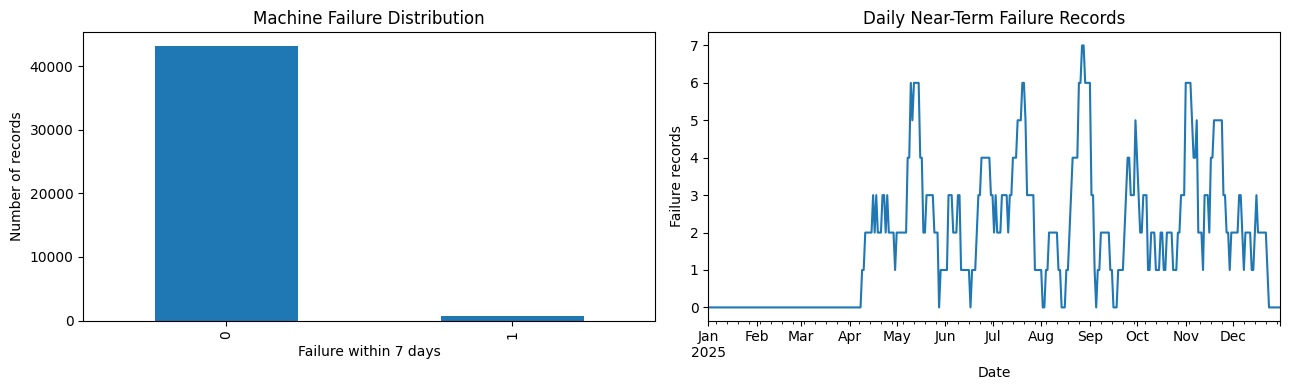

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df["failure_within_7_days"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Machine Failure Distribution")
axes[0].set_xlabel("Failure within 7 days")
axes[0].set_ylabel("Number of records")

daily_failures = (
    df.groupby("date")["failure_within_7_days"].sum()
)

daily_failures.plot(ax=axes[1])

axes[1].set_title("Daily Near-Term Failure Records")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Failure records")

plt.tight_layout()
plt.show()

failure_within_7_days,0,1
vibration,2.969058,5.612887
temperature,59.533694,77.018531
pressure,98.880265,87.461306
current,12.675002,16.999620
rpm,1641.826038,1562.162058
noise_level,58.482758,68.110702


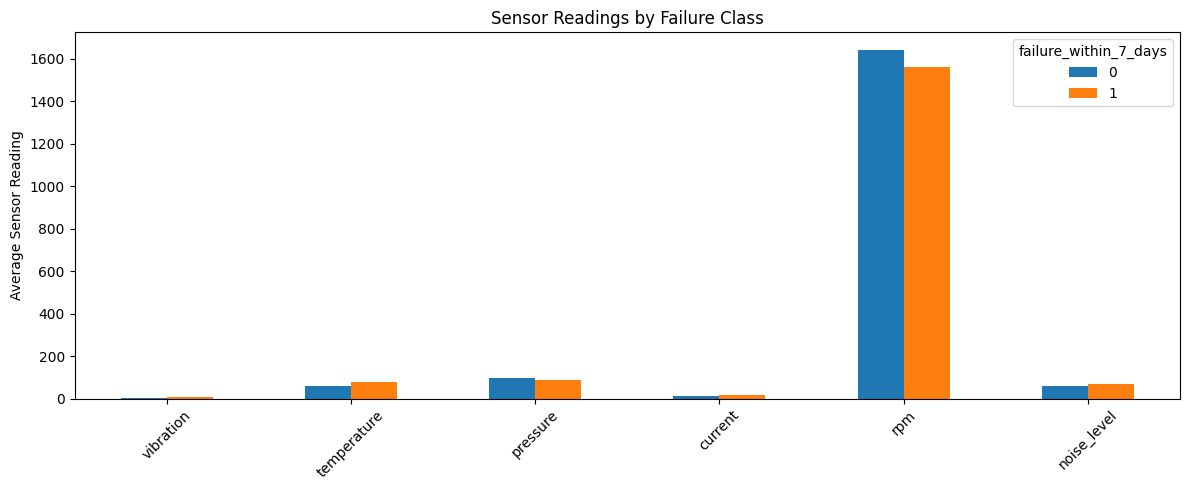

In [5]:
eda_features = [
    "vibration",
    "temperature",
    "pressure",
    "current",
    "rpm",
    "noise_level"
]

group_means = df.groupby(
    "failure_within_7_days"
)[eda_features].mean().T

display(group_means)

group_means.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Sensor Readings by Failure Class")
plt.ylabel("Average Sensor Reading")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

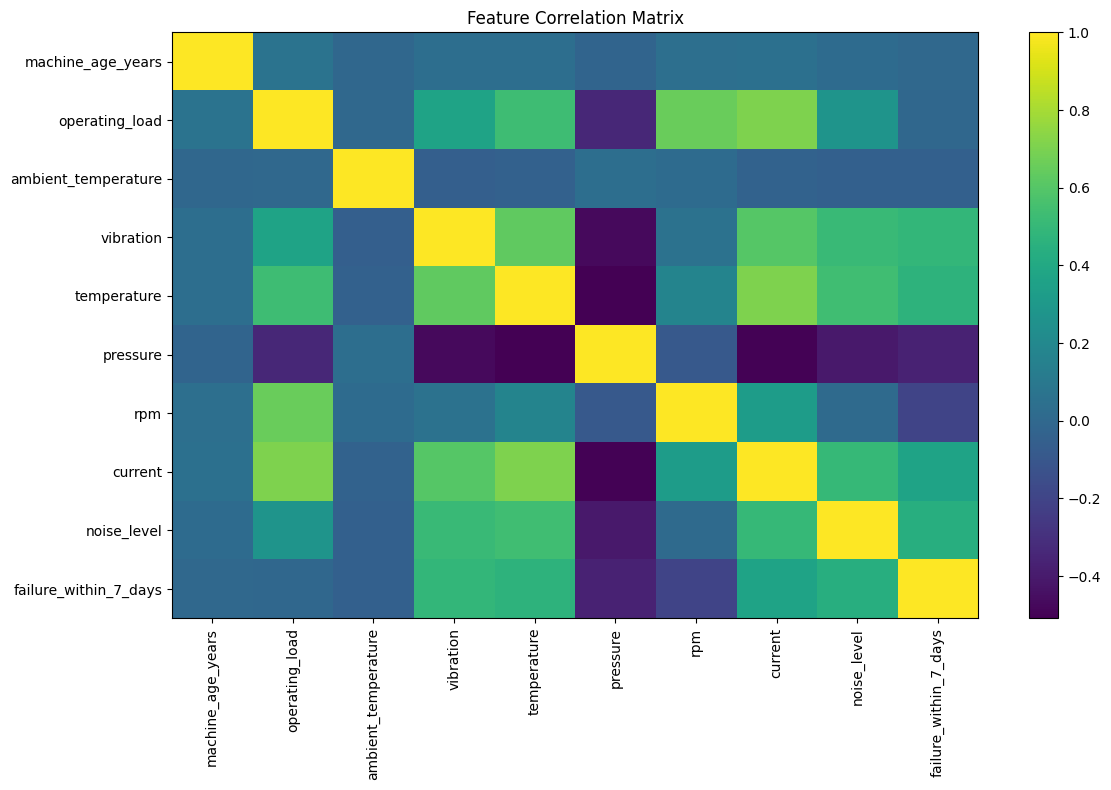

In [7]:
correlation = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 8))

plt.imshow(correlation, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [8]:
df = df.sort_values(
    ["machine_id", "date"]
).copy()

rolling_features = [
    "vibration",
    "temperature",
    "pressure",
    "current",
    "rpm"
]

for col in rolling_features:

    grouped = df.groupby("machine_id")[col]

    df[f"{col}_rolling_mean_7d"] = grouped.transform(
        lambda x: x.rolling(
            window=7,
            min_periods=2
        ).mean()
    )

    df[f"{col}_rolling_std_7d"] = grouped.transform(
        lambda x: x.rolling(
            window=7,
            min_periods=2
        ).std()
    )

    df[f"{col}_change_1d"] = grouped.diff()

df["day_of_week"] = df["date"].dt.dayofweek

df["month"] = df["date"].dt.month

print("Feature engineering completed.")

display(df.head())

Feature engineering completed.


,date,machine_id,machine_type,machine_age_years,operating_load,ambient_temperature,vibration,temperature,pressure,rpm,...,pressure_rolling_std_7d,pressure_change_1d,current_rolling_mean_7d,current_rolling_std_7d,current_change_1d,rpm_rolling_mean_7d,rpm_rolling_std_7d,rpm_change_1d,day_of_week,month
0,2025-01-01,M001,Turbine,12.151602,0.694707,23.810758,2.348048,57.596936,NaN,1635.943792,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1
1,2025-01-02,M001,Turbine,12.151602,0.532813,27.062463,2.985038,50.960065,102.015002,1608.432428,...,NaN,NaN,12.296424,0.963698,-1.362874,1622.188110,19.453472,-27.511364,3,1
2,2025-01-03,M001,Turbine,12.151602,0.642332,24.226463,2.724257,59.962178,101.716394,1631.044156,...,0.211148,-0.298608,12.356096,0.689230,0.860452,1625.140125,14.675216,22.611728,4,1
3,2025-01-04,M001,Turbine,12.151602,0.576546,24.132520,2.496095,55.928595,97.475938,1660.049678,...,2.538823,-4.240456,12.552677,0.686490,0.666980,1633.867514,21.171771,29.005522,5,1
4,2025-01-05,M001,Turbine,12.151602,0.553419,22.164103,2.332167,56.291271,104.591953,1633.057192,...,2.947046,7.116016,12.221850,0.949044,-2.243878,1633.705449,18.338872,-26.992486,6,1


In [9]:
unique_dates = np.sort(df["date"].unique())

train_cut = unique_dates[
    int(len(unique_dates) * 0.70)
]

val_cut = unique_dates[
    int(len(unique_dates) * 0.85)
]

train_df = df[df["date"] < train_cut].copy()

val_df = df[
    (df["date"] >= train_cut) &
    (df["date"] < val_cut)
].copy()

test_df = df[df["date"] >= val_cut].copy()

print("Training data:", train_df.shape)
print("Validation data:", val_df.shape)
print("Testing data:", test_df.shape)

target = "failure_within_7_days"

drop_columns = [
    "date",
    "machine_id",
    target
]

feature_columns = [
    col for col in df.columns
    if col not in drop_columns
]

categorical_features = ["machine_type"]

numeric_features = [
    col for col in feature_columns
    if col not in categorical_features
]

X_train = train_df[feature_columns]
y_train = train_df[target]

X_val = val_df[feature_columns]
y_val = val_df[target]

X_test = test_df[feature_columns]
y_test = test_df[target]

print("Training failure rate:", y_train.mean())
print("Validation failure rate:", y_val.mean())
print("Testing failure rate:", y_test.mean())

Training data: (30600, 30)
Validation data: (6600, 30)
Testing data: (6600, 30)
Training failure rate: 0.013464052287581699
Validation failure rate: 0.019545454545454546
Testing failure rate: 0.018636363636363635


In [10]:
numeric_transformer = Pipeline(steps=[

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler())

])

categorical_transformer = Pipeline(steps=[

    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("onehot", OneHotEncoder(handle_unknown="ignore"))

])

preprocessor = ColumnTransformer(transformers=[

    ("num", numeric_transformer, numeric_features),

    ("cat", categorical_transformer, categorical_features)

])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [11]:
models = {

    "Dummy Baseline": DummyClassifier(
        strategy="prior"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )

}

fitted_models = {}

comparison_results = []

for name, estimator in models.items():

    pipeline = Pipeline(steps=[

        ("preprocess", clone(preprocessor)),

        ("model", estimator)

    ])

    pipeline.fit(X_train, y_train)

    fitted_models[name] = pipeline

    val_prob = pipeline.predict_proba(X_val)[:, 1]

    val_pred = (val_prob >= 0.50).astype(int)

    comparison_results.append({

        "Model": name,

        "Accuracy": accuracy_score(y_val, val_pred),

        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),

        "F1 Score": f1_score(
            y_val, val_pred, zero_division=0
        ),

        "ROC AUC": roc_auc_score(y_val, val_prob),

        "PR AUC": average_precision_score(y_val, val_prob)

    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    "PR AUC",
    ascending=False
)

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
1,Logistic Regression,0.991364,0.697802,0.984496,0.816720,0.999348,0.972685
3,Extra Trees,0.994848,0.802548,0.976744,0.881119,0.999217,0.963291
2,Random Forest,0.994545,0.834532,0.899225,0.865672,0.998879,0.944022
0,Dummy Baseline,0.980455,0.000000,0.000000,0.000000,0.500000,0.019545


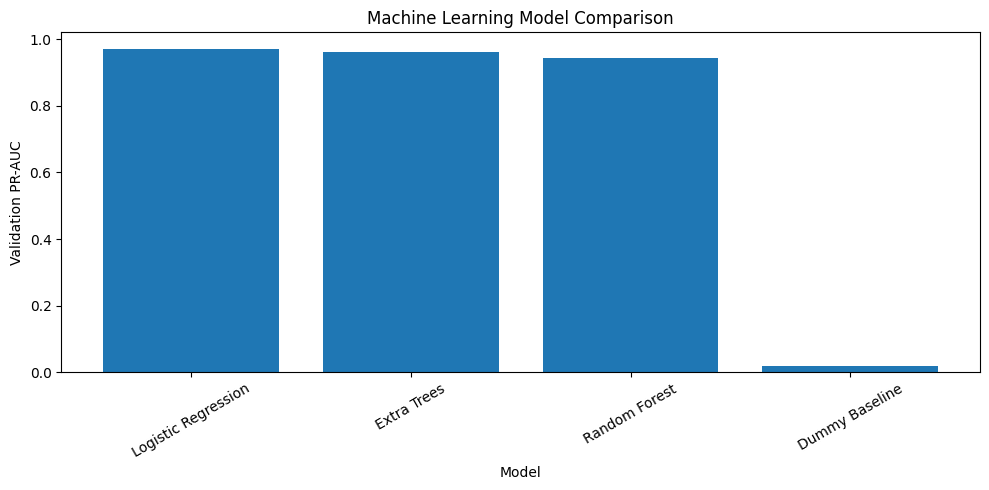

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["PR AUC"]
)

plt.title("Machine Learning Model Comparison")

plt.xlabel("Model")

plt.ylabel("Validation PR-AUC")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [13]:
candidate_scores = comparison_df[
    comparison_df["Model"] != "Dummy Baseline"
]

best_model_name = candidate_scores.iloc[0]["Model"]

best_model = fitted_models[best_model_name]

print("Selected model:", best_model_name)

val_prob = best_model.predict_proba(X_val)[:, 1]

FALSE_NEGATIVE_COST = 10

FALSE_POSITIVE_COST = 1

threshold_results = []

threshold_grid = np.arange(0.05, 0.96, 0.01)

for threshold in threshold_grid:

    pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        pred,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        fn * FALSE_NEGATIVE_COST
        + fp * FALSE_POSITIVE_COST
    )

    threshold_results.append({

        "Threshold": threshold,

        "False Positives": fp,

        "False Negatives": fn,

        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),

        "Recall": recall_score(
            y_val, pred, zero_division=0
        ),

        "Cost": total_cost

    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold = float(
    threshold_df.loc[
        threshold_df["Cost"].idxmin(),
        "Threshold"
    ]
)

print("Optimised threshold:", round(best_threshold, 2))

display(
    threshold_df.sort_values("Cost").head(10)
)

Selected model: Logistic Regression
Optimised threshold: 0.8


,Threshold,False Positives,False Negatives,Precision,Recall,Cost
75,0.80,43,2,0.747059,0.984496,63
74,0.79,44,2,0.742690,0.984496,64
63,0.68,47,2,0.729885,0.984496,67
66,0.71,47,2,0.729885,0.984496,67
72,0.77,47,2,0.729885,0.984496,67
73,0.78,47,2,0.729885,0.984496,67
69,0.74,47,2,0.729885,0.984496,67
68,0.73,47,2,0.729885,0.984496,67
67,0.72,47,2,0.729885,0.984496,67
64,0.69,47,2,0.729885,0.984496,67


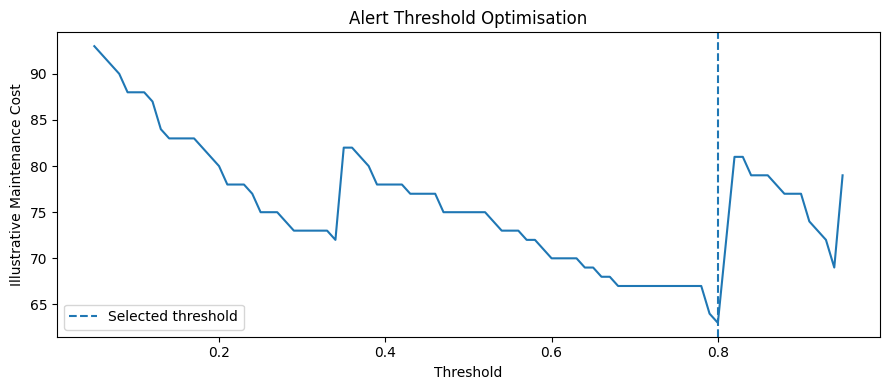

In [14]:
plt.figure(figsize=(9, 4))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Cost"]
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Selected threshold"
)

plt.xlabel("Threshold")

plt.ylabel("Illustrative Maintenance Cost")

plt.title("Alert Threshold Optimisation")

plt.legend()

plt.tight_layout()

plt.show()

In [15]:
test_prob = best_model.predict_proba(X_test)[:, 1]

test_pred = (
    test_prob >= best_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

test_metrics = pd.DataFrame([{

    "Model": best_model_name,

    "Threshold": best_threshold,

    "Accuracy": accuracy_score(y_test, test_pred),

    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),

    "Recall": recall_score(
        y_test, test_pred, zero_division=0
    ),

    "F1 Score": f1_score(
        y_test, test_pred, zero_division=0
    ),

    "ROC AUC": roc_auc_score(y_test, test_prob),

    "PR AUC": average_precision_score(y_test, test_prob),

    "Brier Score": brier_score_loss(y_test, test_prob),

    "False Positives": fp,

    "False Negatives": fn,

    "True Positives": tp,

    "True Negatives": tn

}])

display(test_metrics.T)

print(
    classification_report(
        y_test,
        test_pred,
        zero_division=0
    )
)

,0
Model,Logistic Regression
Threshold,0.8
Accuracy,0.994848
Precision,0.783439
Recall,1.0
F1 Score,0.878571
ROC AUC,0.999657
PR AUC,0.982487
Brier Score,0.00593
False Positives,34


              precision    recall  f1-score   support

           0       1.00      0.99      1.00      6477
           1       0.78      1.00      0.88       123

    accuracy                           0.99      6600
   macro avg       0.89      1.00      0.94      6600
weighted avg       1.00      0.99      1.00      6600



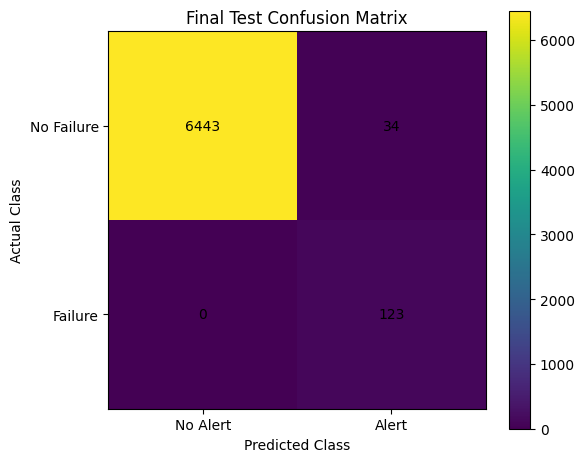

In [16]:
cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Final Test Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["No Alert", "Alert"]
)

plt.yticks(
    [0, 1],
    ["No Failure", "Failure"]
)

for (i, j), value in np.ndenumerate(cm):

    plt.text(
        j,
        i,
        str(value),
        ha="center",
        va="center"
    )

plt.colorbar()

plt.tight_layout()

plt.show()

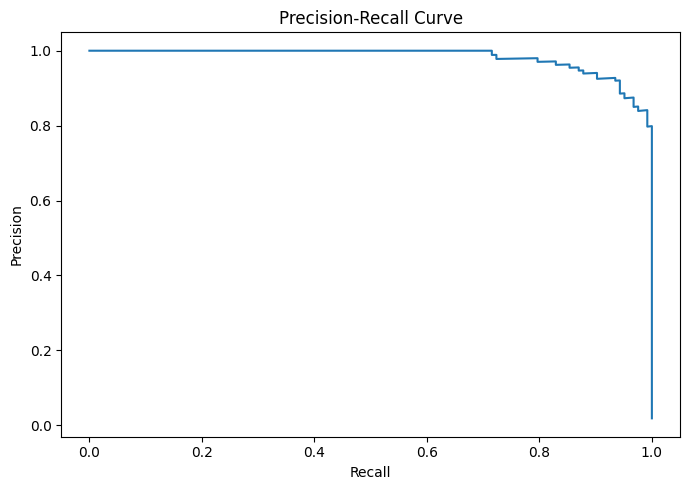

In [17]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(recall, precision)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.tight_layout()

plt.show()

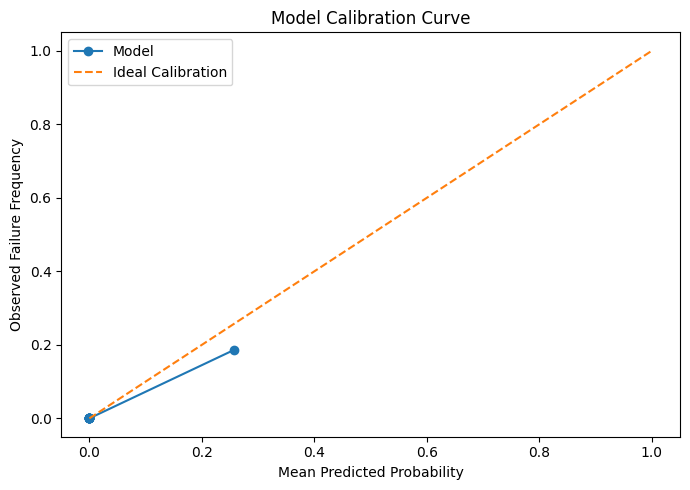

Brier Score: 0.0059


In [18]:
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal Calibration"
)

plt.xlabel("Mean Predicted Probability")

plt.ylabel("Observed Failure Frequency")

plt.title("Model Calibration Curve")

plt.legend()

plt.tight_layout()

plt.show()

print(
    "Brier Score:",
    round(brier_score_loss(y_test, test_prob), 4)
)

In [19]:
permutation_result = permutation_importance(

    best_model,

    X_val,

    y_val,

    scoring="average_precision",

    n_repeats=5,

    random_state=42,

    n_jobs=-1

)

importance_df = pd.DataFrame({

    "Feature": feature_columns,

    "Importance": permutation_result.importances_mean,

    "Standard Deviation": permutation_result.importances_std

})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance,Standard Deviation
13,temperature_rolling_mean_7d,0.163910,0.021211
16,pressure_rolling_mean_7d,0.095303,0.014290
22,rpm_rolling_mean_7d,0.073658,0.009197
4,vibration,0.022423,0.004956
2,operating_load,0.019492,0.003587
5,temperature,0.016030,0.004117
11,vibration_rolling_std_7d,0.006612,0.001637
9,noise_level,0.003343,0.002052
6,pressure,0.002449,0.001002
14,temperature_rolling_std_7d,0.001805,0.001381


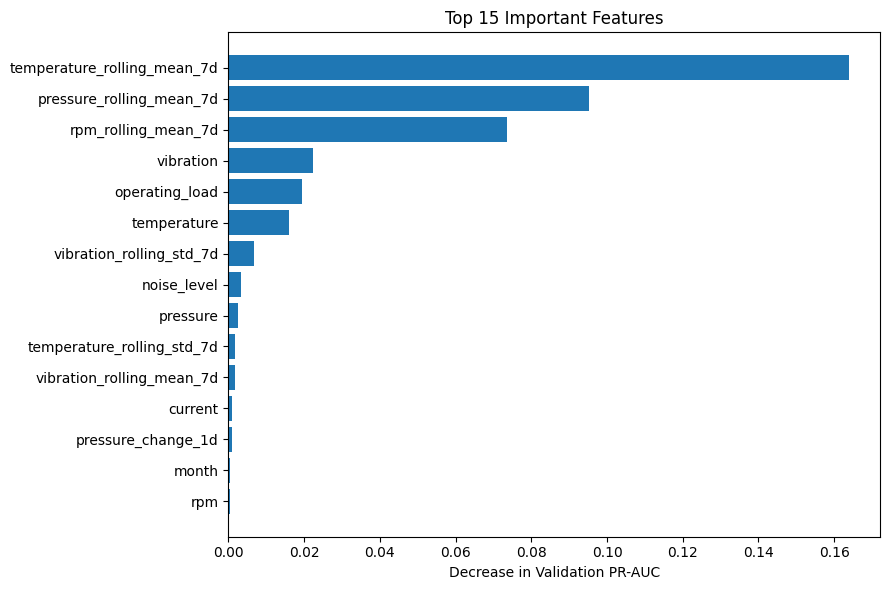

In [20]:
top_features = importance_df.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Decrease in Validation PR-AUC")

plt.title("Top 15 Important Features")

plt.tight_layout()

plt.show()

In [21]:
anomaly_preprocessor = Pipeline(steps=[

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler())

])

normal_train = X_train.loc[
    y_train == 0,
    numeric_features
]

normal_train_transformed = (
    anomaly_preprocessor.fit_transform(normal_train)
)

iso_forest = IsolationForest(

    n_estimators=200,

    contamination=0.03,

    random_state=42

)

iso_forest.fit(normal_train_transformed)

test_anomaly_transformed = (
    anomaly_preprocessor.transform(
        X_test[numeric_features]
    )
)

anomaly_labels = iso_forest.predict(
    test_anomaly_transformed
)

anomaly_scores = -iso_forest.decision_function(
    test_anomaly_transformed
)

print(
    "Anomaly rate:",
    round((anomaly_labels == -1).mean() * 100, 2),
    "%"
)

anomaly_mask = anomaly_labels == -1

if anomaly_mask.any():

    print(
        "Failure rate among anomalies:",
        round(y_test[anomaly_mask].mean() * 100, 2),
        "%"
    )

Anomaly rate: 6.0 %
Failure rate among anomalies: 31.06 %


In [22]:
test_results = test_df[
    ["date", "machine_id", "machine_type"]
].copy()

test_results["Actual Failure"] = y_test.values

test_results["Failure Probability"] = test_prob

test_results["Predicted Alert"] = test_pred

test_results["Anomaly Flag"] = (
    anomaly_labels == -1
).astype(int)

test_results["Anomaly Score"] = anomaly_scores

watch_threshold = best_threshold * 0.5

test_results["Maintenance Priority"] = np.select(

    [

        test_results["Failure Probability"] >= best_threshold,

        (
            test_results["Failure Probability"] >= watch_threshold
        ) | (
            test_results["Anomaly Flag"] == 1
        )

    ],

    [

        "High",

        "Watch"

    ],

    default="Normal"

)

display(
    test_results.sort_values(
        "Failure Probability",
        ascending=False
    ).head(20)
)

,date,machine_id,machine_type,Actual Failure,Failure Probability,Predicted Alert,Anomaly Flag,Anomaly Score,Maintenance Priority
16781,2025-12-23,M046,Pump,1,1.0,1,1,0.106065,High
39731,2025-11-08,M109,Pump,1,1.0,1,1,0.142374,High
9818,2025-11-25,M027,Compressor,1,1.0,1,1,0.132025,High
29888,2025-11-20,M082,Compressor,1,1.0,1,1,0.124690,High
15296,2025-11-28,M042,Turbine,1,1.0,1,1,0.111179,High
8361,2025-11-28,M023,Turbine,1,1.0,1,1,0.117975,High
7627,2025-11-24,M021,Pump,1,1.0,1,1,0.108761,High
15295,2025-11-27,M042,Turbine,1,1.0,1,1,0.133375,High
16779,2025-12-21,M046,Pump,1,1.0,1,1,0.121777,High
20065,2025-12-22,M055,Compressor,1,1.0,1,1,0.117859,High


In [23]:
latest_machine_status = (

    test_results.sort_values("date")

    .groupby("machine_id", as_index=False)

    .tail(1)

    .sort_values(
        "Failure Probability",
        ascending=False
    )

)

display(
    latest_machine_status.head(25)
)

,date,machine_id,machine_type,Actual Failure,Failure Probability,Predicted Alert,Anomaly Flag,Anomaly Score,Maintenance Priority
13504,2025-12-31,M037,Compressor,0,1.001977e-13,0,0,-0.078861,Normal
21534,2025-12-31,M059,Turbine,0,2.475027e-14,0,0,-0.074373,Normal
1094,2025-12-31,M003,Pump,0,1.744591e-14,0,0,-0.076689,Normal
6934,2025-12-31,M019,Pump,0,1.684757e-14,0,0,-0.077399,Normal
28104,2025-12-31,M077,Pump,0,1.142004e-14,0,0,-0.131133,Normal
2919,2025-12-31,M008,Pump,0,4.505017e-15,0,0,-0.063124,Normal
42704,2025-12-31,M117,Compressor,0,4.357060e-15,0,0,-0.086784,Normal
9489,2025-12-31,M026,Pump,0,3.772070e-15,0,0,-0.065459,Normal
2189,2025-12-31,M006,Compressor,0,2.985143e-15,0,0,-0.068827,Normal
16424,2025-12-31,M045,Compressor,0,2.016682e-15,0,0,-0.109704,Normal


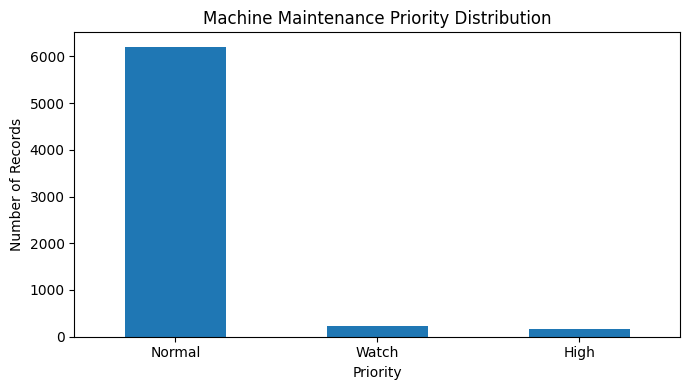

In [24]:
priority_counts = (
    test_results["Maintenance Priority"]
    .value_counts()
)

priority_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Machine Maintenance Priority Distribution")

plt.xlabel("Priority")

plt.ylabel("Number of Records")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

In [25]:
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

test_metrics.to_csv(
    "test_evaluation_metrics.csv",
    index=False
)

test_results.to_csv(
    "test_predictions_and_alerts.csv",
    index=False
)

latest_machine_status.to_csv(
    "latest_machine_priority_summary.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

df.to_csv(
    "synthetic_machine_sensor_dataset.csv",
    index=False
)

print("All project files exported successfully.")

All project files exported successfully.


In [26]:
from google.colab import files

files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from google.colab import files

files.download("test_evaluation_metrics.csv")

files.download("test_predictions_and_alerts.csv")

files.download("latest_machine_priority_summary.csv")

files.download("feature_importance.csv")

files.download("synthetic_machine_sensor_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>